In [1]:

from pathlib import Path
import pandas as pd

# Dataset location
DATASET_DIR = Path("dataset/Audio_Speech_Actors_01-24_16k")

# Emotion labels
emotion_map = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}

# Find audio files
audio_files = sorted(DATASET_DIR.glob("Actor_*/*.wav"))

records = []

for file in audio_files:
    parts = file.stem.split("-")

    if len(parts) == 7 and parts[2] in emotion_map:
        records.append({
            "file_path": str(file),
            "emotion": emotion_map[parts[2]],
            "actor": parts[6]
        })

df = pd.DataFrame(records)

print("Total audio files:", len(audio_files))
print("Valid recordings:", len(df))

print("\nEmotion distribution:")
print(df["emotion"].value_counts())

display(df.head())


Total audio files: 1440
Valid recordings: 1440

Emotion distribution:
emotion
calm         192
happy        192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
neutral       96
Name: count, dtype: int64


,file_path,emotion,actor
0,dataset\Audio_Speech_Actors_01-24_16k\Actor_01...,neutral,01
1,dataset\Audio_Speech_Actors_01-24_16k\Actor_01...,neutral,01
2,dataset\Audio_Speech_Actors_01-24_16k\Actor_01...,neutral,01
3,dataset\Audio_Speech_Actors_01-24_16k\Actor_01...,neutral,01
4,dataset\Audio_Speech_Actors_01-24_16k\Actor_01...,calm,01


In [2]:

import librosa
import numpy as np

# Select the first audio file
sample_file = df.iloc[0]["file_path"]

# Load audio
audio, sample_rate = librosa.load(
    sample_file,
    sr=16000
)

# Extract MFCC features
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sample_rate,
    n_mfcc=40
)

print("Audio shape:", audio.shape)
print("Sample rate:", sample_rate)
print("MFCC shape:", mfcc.shape)


Audio shape: (52853,)
Sample rate: 16000
MFCC shape: (40, 104)


In [3]:
import numpy as np
import librosa

features = []
labels = []

for index, row in df.iterrows():
    audio, sample_rate = librosa.load(
        row["file_path"],
        sr=16000
    )

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sample_rate,
        n_mfcc=40
    )

    # Average MFCC values across time
    mfcc_features = np.mean(mfcc, axis=1)

    features.append(mfcc_features)
    labels.append(row["emotion"])

X = np.array(features)
y = np.array(labels)

print("Feature dataset shape:", X.shape)
print("Label dataset shape:", y.shape)
print("Feature extraction completed!")

Feature dataset shape: (1440, 40)
Label dataset shape: (1440,)
Feature extraction completed!


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Convert emotion names into numerical labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Normalize feature values
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nEmotion classes:", label_encoder.classes_)

Training features: (1152, 40)
Testing features: (288, 40)
Training labels: (1152,)
Testing labels: (288,)

Emotion classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

# Build the neural network
model = Sequential([
    Input(shape=(40,)),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(128, activation="relu"),
    Dropout(0.2),

    Dense(64, activation="relu"),

    Dense(8, activation="softmax")
])

# Configure the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        10,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,168 (203.78 KB)

 Trainable params: 52,168 (203.78 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.2096 - loss: 2.0186 - val_accuracy: 0.2554 - val_loss: 1.8987
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3051 - loss: 1.8471 - val_accuracy: 0.3203 - val_loss: 1.7873
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3822 - loss: 1.6689 - val_accuracy: 0.3377 - val_loss: 1.6713
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4202 - loss: 1.5641 - val_accuracy: 0.3939 - val_loss: 1.6022
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4919 - loss: 1.4186 - val_accuracy: 0.4416 - val_loss: 1.5389
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5331 - loss: 1.3214 - val_accuracy: 0.4545 - val_loss: 1.4803
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5309 - loss: 1.2543 - val_accuracy: 0.4805 - val_loss: 1.4478
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5907 - loss: 1.1665 - val_accuracy: 0.4762 - 

In [7]:
# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5486 - loss: 1.3064 
Test Loss: 1.3064
Test Accuracy: 54.86%


In [8]:
from sklearn.metrics import classification_report
import numpy as np

# Predict emotions for test recordings
y_pred_prob = model.predict(X_test)

# Convert probabilities into emotion labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Generate classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
              precision    recall  f1-score   support

       angry       0.71      0.76      0.73        38
        calm       0.70      0.42      0.52        38
     disgust       0.54      0.68      0.60        38
     fearful       0.53      0.74      0.62        39
       happy       0.52      0.41      0.46        39
     neutral       0.28      0.37      0.32        19
         sad       0.47      0.47      0.47        38
   surprised       0.63      0.44      0.52        39

    accuracy                           0.55       288
   macro avg       0.55      0.54      0.53       288
weighted avg       0.56      0.55      0.54       288



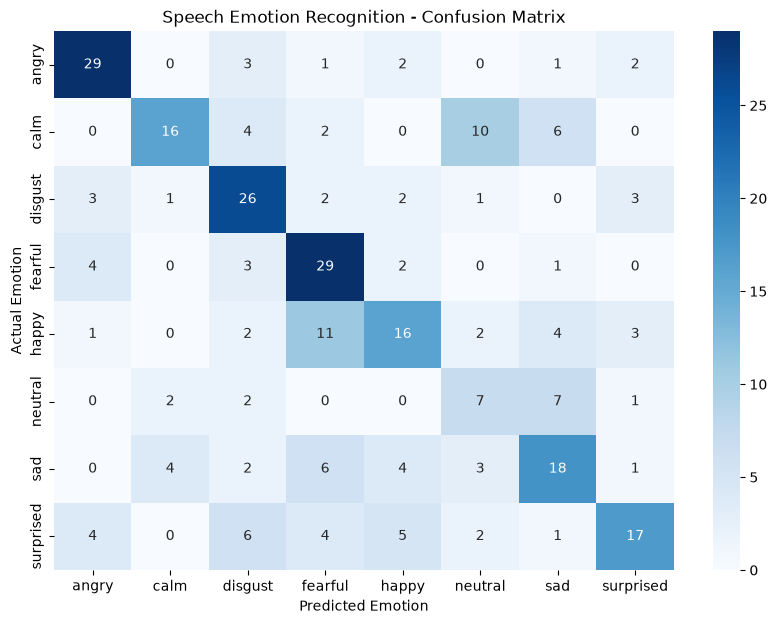

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Speech Emotion Recognition - Confusion Matrix")
plt.show()

In [10]:
import numpy as np
import librosa

MAX_LEN = 130

sequence_features = []

for file_path in df["file_path"]:
    audio, sr = librosa.load(file_path, sr=16000)

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    # Pad or truncate to 130 time frames
    if mfcc.shape[1] < MAX_LEN:
        mfcc = np.pad(
            mfcc,
            ((0, 0), (0, MAX_LEN - mfcc.shape[1])),
            mode="constant"
        )
    else:
        mfcc = mfcc[:, :MAX_LEN]

    sequence_features.append(mfcc.T)

X_cnn = np.array(sequence_features)

print("CNN feature shape:", X_cnn.shape)

CNN feature shape: (1440, 130, 40)


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset
X_cnn_train, X_cnn_test, y_cnn_train, y_cnn_test = train_test_split(
    X_cnn,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Normalize MFCC features
scaler_cnn = StandardScaler()

X_cnn_train = scaler_cnn.fit_transform(
    X_cnn_train.reshape(-1, 40)
).reshape(-1, 130, 40)

X_cnn_test = scaler_cnn.transform(
    X_cnn_test.reshape(-1, 40)
).reshape(-1, 130, 40)

print("CNN training shape:", X_cnn_train.shape)
print("CNN testing shape:", X_cnn_test.shape)

CNN training shape: (1152, 130, 40)
CNN testing shape: (288, 130, 40)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout
)

cnn_model = Sequential([
    Input(shape=(130, 40)),

    Conv1D(64, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),

    Conv1D(128, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),

    GlobalAveragePooling1D(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(8, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         7,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 62, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 31, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,736 (225.53 KB)

 Trainable params: 57,736 (225.53 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

cnn_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    X_cnn_train,
    y_cnn_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[cnn_early_stopping],
    verbose=1
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.1553 - loss: 2.0683 - val_accuracy: 0.1515 - val_loss: 2.0126
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1987 - loss: 1.9933 - val_accuracy: 0.3030 - val_loss: 1.8867
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2584 - loss: 1.8910 - val_accuracy: 0.2641 - val_loss: 1.7840
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3246 - loss: 1.7492 - val_accuracy: 0.3463 - val_loss: 1.6644
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3529 - loss: 1.6923 - val_accuracy: 0.3506 - val_loss: 1.6388
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4126 - loss: 1.5613 - val_accuracy: 0.4113 - val_loss: 1.5196
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4408 - loss: 1.4979 - val_accuracy: 0.4069 - val_loss: 1.4675
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5038 - loss: 1.3808 - val_accuracy: 0.

In [14]:
# Evaluate CNN on unseen test recordings
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_cnn_test,
    y_cnn_test,
    verbose=1
)

print(f"CNN Test Loss: {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5764 - loss: 1.1099 
CNN Test Loss: 1.1099
CNN Test Accuracy: 57.64%


In [15]:
from sklearn.metrics import classification_report
import numpy as np

# Predict emotions using CNN
cnn_predictions = cnn_model.predict(X_cnn_test)

cnn_y_pred = np.argmax(cnn_predictions, axis=1)

# Classification report
print(classification_report(
    y_cnn_test,
    cnn_y_pred,
    target_names=label_encoder.classes_
))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step  
              precision    recall  f1-score   support

       angry       0.81      0.68      0.74        38
        calm       0.70      0.68      0.69        38
     disgust       0.61      0.58      0.59        38
     fearful       0.57      0.51      0.54        39
       happy       0.33      0.28      0.31        39
     neutral       0.35      0.68      0.46        19
         sad       0.48      0.37      0.42        38
   surprised       0.69      0.87      0.77        39

    accuracy                           0.58       288
   macro avg       0.57      0.58      0.57       288
weighted avg       0.58      0.58      0.57       288



In [16]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Keep recordings from each actor together
groups = df["actor"].values

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_cnn, y_encoded, groups)
)

# Split features and labels
X_train_new = X_cnn[train_idx]
X_test_new = X_cnn[test_idx]

y_train_new = y_encoded[train_idx]
y_test_new = y_encoded[test_idx]

# Normalize using training data only
new_scaler = StandardScaler()

X_train_new = new_scaler.fit_transform(
    X_train_new.reshape(-1, 40)
).reshape(-1, 130, 40)

X_test_new = new_scaler.transform(
    X_test_new.reshape(-1, 40)
).reshape(-1, 130, 40)

print("Training recordings:", len(train_idx))
print("Testing recordings:", len(test_idx))

print("Training actors:", sorted(set(groups[train_idx])))
print("Testing actors:", sorted(set(groups[test_idx])))

Training recordings: 1140
Testing recordings: 300
Training actors: ['02', '03', '04', '05', '06', '07', '08', '10', '11', '13', '14', '15', '16', '18', '20', '21', '22', '23', '24']
Testing actors: ['01', '09', '12', '17', '19']


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# Build a fresh CNN
actor_cnn = Sequential([
    Input(shape=(130, 40)),

    Conv1D(64, 3, activation="relu"),
    MaxPooling1D(2),

    Conv1D(128, 3, activation="relu"),
    MaxPooling1D(2),

    GlobalAveragePooling1D(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(8, activation="softmax")
])

actor_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train using actor-independent data
actor_history = actor_cnn.fit(
    X_train_new,
    y_train_new,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.1502 - loss: 2.0744 - val_accuracy: 0.2193 - val_loss: 2.0041
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2314 - loss: 1.9467 - val_accuracy: 0.2456 - val_loss: 1.9252
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2774 - loss: 1.8073 - val_accuracy: 0.3860 - val_loss: 1.7982
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3092 - loss: 1.7234 - val_accuracy: 0.4035 - val_loss: 1.7001
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3739 - loss: 1.6290 - val_accuracy: 0.3114 - val_loss: 1.6448
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4189 - loss: 1.5173 - val_accuracy: 0.3640 - val_loss: 1.5671
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4364 - loss: 1.4689 - val_accuracy: 0.4079 - val_loss: 1.5313
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4737 - loss: 1.3867 - val_accuracy: 0.

In [18]:
actor_test_loss, actor_test_accuracy = actor_cnn.evaluate(
    X_test_new,
    y_test_new
)

print("Actor-independent Test Loss:", actor_test_loss)
print("Actor-independent Test Accuracy:", actor_test_accuracy * 100)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3600 - loss: 1.8318
Actor-independent Test Loss: 1.8318408727645874
Actor-independent Test Accuracy: 36.000001430511475


In [19]:
from sklearn.metrics import classification_report

actor_predictions = actor_cnn.predict(X_test_new)

actor_predicted_labels = actor_predictions.argmax(axis=1)

print(classification_report(
    y_test_new,
    actor_predicted_labels,
    target_names=label_encoder.classes_
))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
              precision    recall  f1-score   support

       angry       0.40      0.60      0.48        40
        calm       0.45      0.35      0.39        40
     disgust       0.40      0.47      0.44        40
     fearful       0.54      0.35      0.42        40
       happy       0.60      0.07      0.13        40
     neutral       0.50      0.05      0.09        20
         sad       0.18      0.47      0.26        40
   surprised       0.64      0.35      0.45        40

    accuracy                           0.36       300
   macro avg       0.46      0.34      0.33       300
weighted avg       0.46      0.36      0.35       300



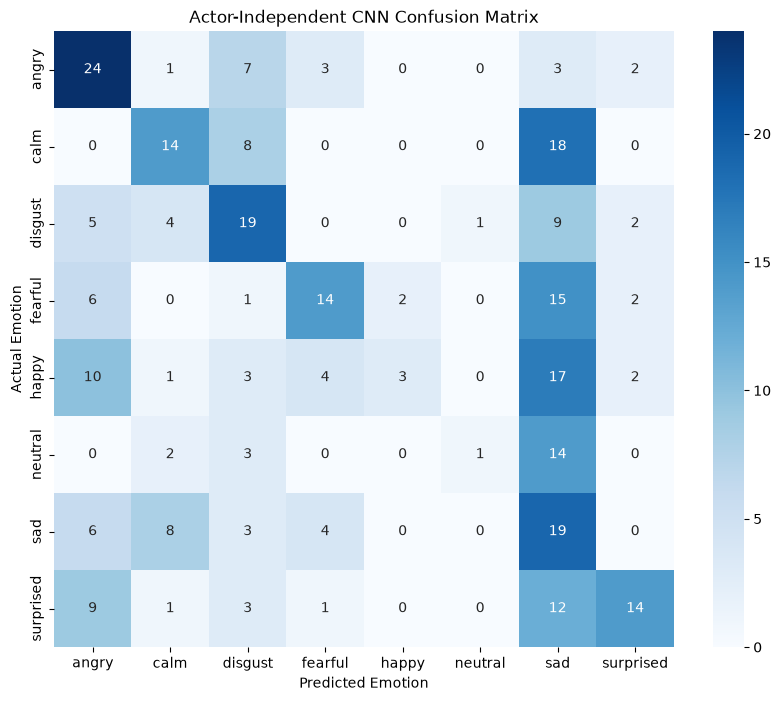

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_actor = confusion_matrix(
    y_test_new,
    actor_predicted_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_actor,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Actor-Independent CNN Confusion Matrix")

plt.show()

In [21]:
import numpy as np
import librosa

def extract_improved_features(file_path):
    audio, sr = librosa.load(file_path, sr=16000)

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        np.mean(delta, axis=1),
        np.mean(delta2, axis=1)
    ])

    return features

In [22]:
improved_features = []

for file_path in df["file_path"]:
    improved_features.append(
        extract_improved_features(file_path)
    )

X_improved = np.array(improved_features)

print("Improved feature shape:", X_improved.shape)

Improved feature shape: (1440, 160)


In [23]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

groups = df["actor"].values

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_improved, y_encoded, groups)
)

X_train_improved = X_improved[train_idx]
X_test_improved = X_improved[test_idx]

y_train_improved = y_encoded[train_idx]
y_test_improved = y_encoded[test_idx]

improved_scaler = StandardScaler()

X_train_improved = improved_scaler.fit_transform(X_train_improved)
X_test_improved = improved_scaler.transform(X_test_improved)

print("Training shape:", X_train_improved.shape)
print("Testing shape:", X_test_improved.shape)
print("Training actors:", sorted(set(groups[train_idx])))
print("Testing actors:", sorted(set(groups[test_idx])))

Training shape: (1140, 160)
Testing shape: (300, 160)
Training actors: ['02', '03', '04', '05', '06', '07', '08', '10', '11', '13', '14', '15', '16', '18', '20', '21', '22', '23', '24']
Testing actors: ['01', '09', '12', '17', '19']


In [24]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

improved_model = Sequential([
    Input(shape=(160,)),

    Dense(256, activation="relu"),
    Dropout(0.4),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),

    Dense(8, activation="softmax")
])

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

improved_history = improved_model.fit(
    X_train_improved,
    y_train_improved,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.1776 - loss: 2.1406 - val_accuracy: 0.2149 - val_loss: 1.9390
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2763 - loss: 1.8698 - val_accuracy: 0.2675 - val_loss: 1.8432
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3783 - loss: 1.6902 - val_accuracy: 0.3070 - val_loss: 1.7636
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4529 - loss: 1.4907 - val_accuracy: 0.3816 - val_loss: 1.6711
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5066 - loss: 1.3496 - val_accuracy: 0.4298 - val_loss: 1.5809
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5482 - loss: 1.2193 - val_accuracy: 0.3816 - val_loss: 1.5440
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5833 - loss: 1.1388 - val_accuracy: 0.4254 - val_loss: 1.4974
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6239 - loss: 1.0314 - val_accuracy: 0.4123 - 

In [25]:
improved_test_loss, improved_test_accuracy = improved_model.evaluate(
    X_test_improved,
    y_test_improved
)

print("Improved ANN Test Loss:", improved_test_loss)
print("Improved ANN Test Accuracy:", improved_test_accuracy * 100)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4100 - loss: 2.0662 
Improved ANN Test Loss: 2.0661699771881104
Improved ANN Test Accuracy: 40.99999964237213


In [26]:
from sklearn.metrics import classification_report

improved_predictions = improved_model.predict(X_test_improved)

improved_predicted_labels = improved_predictions.argmax(axis=1)

print(classification_report(
    y_test_improved,
    improved_predicted_labels,
    target_names=label_encoder.classes_
))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
              precision    recall  f1-score   support

       angry       0.71      0.60      0.65        40
        calm       0.32      0.82      0.46        40
     disgust       0.33      0.23      0.27        40
     fearful       0.40      0.53      0.46        40
       happy       0.52      0.33      0.40        40
     neutral       0.29      0.25      0.27        20
         sad       0.30      0.17      0.22        40
   surprised       0.61      0.28      0.38        40

    accuracy                           0.41       300
   macro avg       0.44      0.40      0.39       300
weighted avg       0.45      0.41      0.40       300



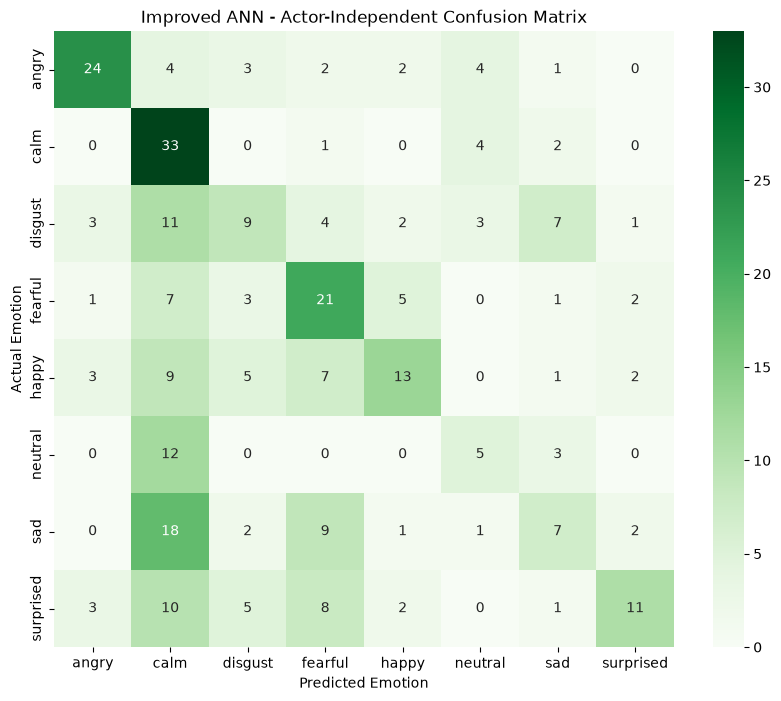

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_improved = confusion_matrix(
    y_test_improved,
    improved_predicted_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_improved,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Improved ANN - Actor-Independent Confusion Matrix")

plt.show()

In [28]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Original CNN",
        "Improved ANN"
    ],
    "Test Accuracy (%)": [
        36.00,
        41.00
    ],
    "Evaluation": [
        "Actor-independent",
        "Actor-independent"
    ]
})

display(model_comparison)

,Model,Test Accuracy (%),Evaluation
0,Original CNN,36.0,Actor-independent
1,Improved ANN,41.0,Actor-independent


In [29]:
import joblib

# Save trained model
improved_model.save("emotion_model.keras")

# Save feature scaler
joblib.dump(improved_scaler, "emotion_scaler.pkl")

# Save emotion label encoder
joblib.dump(label_encoder, "label_encoder.pkl")

print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [30]:
import numpy as np
import librosa

def predict_emotion(file_path):

    # Load audio
    audio, sr = librosa.load(file_path, sr=16000)

    # Extract MFCC features
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    # Extract delta features
    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    # Combine features
    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        np.mean(delta, axis=1),
        np.mean(delta2, axis=1)
    ])

    # Scale features
    features = improved_scaler.transform(
        features.reshape(1, -1)
    )

    # Predict emotion
    prediction = improved_model.predict(
        features,
        verbose=0
    )

    predicted_index = np.argmax(prediction)

    emotion = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = np.max(prediction) * 100

    print("Predicted Emotion:", emotion)
    print(f"Prediction Confidence: {confidence:.2f}%")

    return emotion

In [31]:
sample_audio = df["file_path"].iloc[0]

predict_emotion(sample_audio)

Predicted Emotion: neutral
Prediction Confidence: 39.77%


np.str_('neutral')

In [33]:
unseen_audio = df[
    df["actor"].isin(["01", "09", "12", "17", "19"])
]["file_path"].iloc[0]

predict_emotion(unseen_audio)

Predicted Emotion: neutral
Prediction Confidence: 39.77%


np.str_('neutral')

In [34]:
unseen_row = df[
    df["actor"].isin(["01", "09", "12", "17", "19"])
].iloc[0]

print("Audio file:", unseen_row["file_path"])
print("Actor:", unseen_row["actor"])
print("Actual Emotion:", unseen_row["emotion"])

predict_emotion(unseen_row["file_path"])

Audio file: dataset\Audio_Speech_Actors_01-24_16k\Actor_01\03-01-01-01-01-01-01.wav
Actor: 01
Actual Emotion: neutral
Predicted Emotion: neutral
Prediction Confidence: 39.77%


np.str_('neutral')

In [35]:
unseen_row = df[
    df["actor"].isin(["01", "09", "12", "17", "19"])
].iloc[5]

print("Audio file:", unseen_row["file_path"])
print("Actor:", unseen_row["actor"])
print("Actual Emotion:", unseen_row["emotion"])

predict_emotion(unseen_row["file_path"])

Audio file: dataset\Audio_Speech_Actors_01-24_16k\Actor_01\03-01-02-01-01-02-01.wav
Actor: 01
Actual Emotion: calm
Predicted Emotion: calm
Prediction Confidence: 61.98%


np.str_('calm')

In [36]:
from sklearn.metrics import accuracy_score

unseen_df = df[
    df["actor"].isin(["01", "09", "12", "17", "19"])
].sample(10, random_state=42)

actual = []
predicted = []

for _, row in unseen_df.iterrows():
    features = extract_improved_features(row["file_path"])
    features = improved_scaler.transform(features.reshape(1, -1))

    probabilities = improved_model.predict(features, verbose=0)
    predicted_index = np.argmax(probabilities)

    actual.append(row["emotion"])
    predicted.append(
        label_encoder.inverse_transform([predicted_index])[0]
    )

results = pd.DataFrame({
    "Actor": unseen_df["actor"].values,
    "Actual Emotion": actual,
    "Predicted Emotion": predicted
})

display(results)

accuracy = accuracy_score(actual, predicted) * 100
print(f"Accuracy on 10 unseen recordings: {accuracy:.2f}%")

,Actor,Actual Emotion,Predicted Emotion
0,17,sad,sad
1,19,sad,calm
2,12,angry,angry
3,01,calm,calm
4,17,surprised,fearful
5,17,disgust,calm
6,17,happy,fearful
7,09,disgust,calm
8,01,calm,calm
9,12,surprised,surprised


Accuracy on 10 unseen recordings: 50.00%


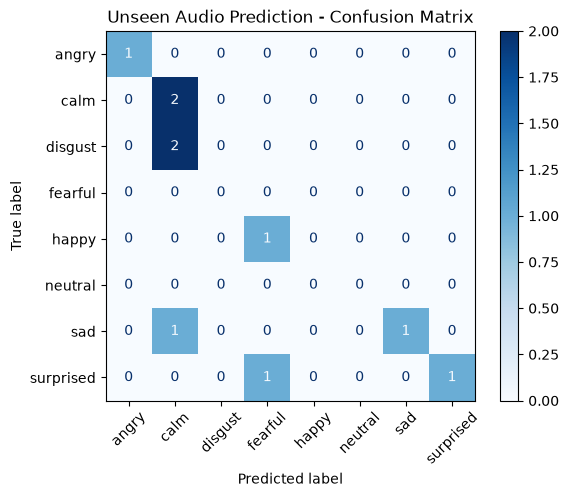

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    actual,
    predicted,
    labels=label_encoder.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Unseen Audio Prediction - Confusion Matrix")
plt.show()

In [38]:
print("Confusion Matrix:")
print(cm)

print("\nEmotion Labels:")
print(label_encoder.classes_)

Confusion Matrix:
[[1 0 0 0 0 0 0 0]
 [0 2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 1 0]
 [0 0 0 1 0 0 0 1]]

Emotion Labels:
['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


In [39]:
evaluation_summary = pd.DataFrame({
    "Model": [
        "Original ANN",
        "Original CNN",
        "Actor-independent CNN",
        "Improved ANN",
        "10-sample unseen test"
    ],
    "Accuracy (%)": [
        54.86,
        57.64,
        36.00,
        41.00,
        50.00
    ],
    "Evaluation": [
        "Random split",
        "Random split",
        "Unseen actors",
        "Unseen actors",
        "10 unseen recordings"
    ]
})

display(evaluation_summary)


,Model,Accuracy (%),Evaluation
0,Original ANN,54.86,Random split
1,Original CNN,57.64,Random split
2,Actor-independent CNN,36.00,Unseen actors
3,Improved ANN,41.00,Unseen actors
4,10-sample unseen test,50.00,10 unseen recordings


In [40]:
import os

files = [
    "emotion_model.keras",
    "emotion_scaler.pkl",
    "label_encoder.pkl"
]

for file in files:
    print(file, "->", "Found" if os.path.exists(file) else "Missing")

emotion_model.keras -> Found
emotion_scaler.pkl -> Found
label_encoder.pkl -> Found


In [41]:
import tensorflow as tf
import joblib

loaded_model = tf.keras.models.load_model("emotion_model.keras")
loaded_scaler = joblib.load("emotion_scaler.pkl")
loaded_encoder = joblib.load("label_encoder.pkl")

print("Model loaded:", loaded_model is not None)
print("Scaler loaded:", loaded_scaler is not None)
print("Label encoder loaded:", loaded_encoder is not None)
print("Emotion classes:", loaded_encoder.classes_)

Model loaded: True
Scaler loaded: True
Label encoder loaded: True
Emotion classes: ['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']


In [42]:
def predict_with_saved_model(file_path):
    audio, sr = librosa.load(file_path, sr=16000)

    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)
    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        np.mean(delta, axis=1),
        np.mean(delta2, axis=1)
    ])

    features = loaded_scaler.transform(features.reshape(1, -1))

    probabilities = loaded_model.predict(features, verbose=0)
    predicted_index = np.argmax(probabilities)

    emotion = loaded_encoder.inverse_transform([predicted_index])[0]
    confidence = np.max(probabilities) * 100

    print("Predicted Emotion:", emotion)
    print(f"Confidence: {confidence:.2f}%")

predict_with_saved_model(unseen_row["file_path"])

Predicted Emotion: calm
Confidence: 61.98%


In [43]:
import os

files = [
    "emotion_model.keras",
    "emotion_scaler.pkl",
    "label_encoder.pkl"
]

for file in files:
    if os.path.exists(file):
        print(f"✓ {file} - Saved")
    else:
        print(f"✗ {file} - Missing")

✓ emotion_model.keras - Saved
✓ emotion_scaler.pkl - Saved
✓ label_encoder.pkl - Saved


In [44]:
import tensorflow as tf
import joblib
import numpy as np
import librosa

# Load saved artifacts
model = tf.keras.models.load_model("emotion_model.keras")
scaler = joblib.load("emotion_scaler.pkl")
encoder = joblib.load("label_encoder.pkl")

def predict_saved_model(file_path):
    audio, sr = librosa.load(file_path, sr=16000)

    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)
    delta = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)

    features = np.concatenate([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),
        np.mean(delta, axis=1),
        np.mean(delta2, axis=1)
    ])

    features = scaler.transform(features.reshape(1, -1))

    probabilities = model.predict(features, verbose=0)
    predicted_index = np.argmax(probabilities)

    emotion = encoder.inverse_transform([predicted_index])[0]
    confidence = np.max(probabilities) * 100

    print("Predicted Emotion:", emotion)
    print(f"Prediction Score: {confidence:.2f}%")

    return emotion

# Test with one audio recording
predict_saved_model(df["file_path"].iloc[5])

Predicted Emotion: calm
Prediction Score: 61.98%


np.str_('calm')